In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/Rabii_2026-10-18/measurements_23:27.csv", skipinitialspace=True)
df

,Size,Type,Time
0,100,Sequential,0.000006
1,100,Parallel,0.007326
2,100,Built-in,0.000007
3,100,Sequential,0.000007
4,100,Parallel,0.009111
...,...,...,...
70,1000000,Parallel,0.152741
71,1000000,Built-in,0.136892
72,1000000,Sequential,0.130596
73,1000000,Parallel,0.163294


In [3]:
df.groupby(["Size", "Type"])["Time"].mean().unstack()

Type,Built-in,Parallel,Sequential
Size,,,
100,0.000006,0.008335,0.000007
1000,0.000075,0.033333,0.000074
10000,0.000913,0.056467,0.001004
100000,0.011987,0.079727,0.011437
1000000,0.136278,0.161607,0.133891


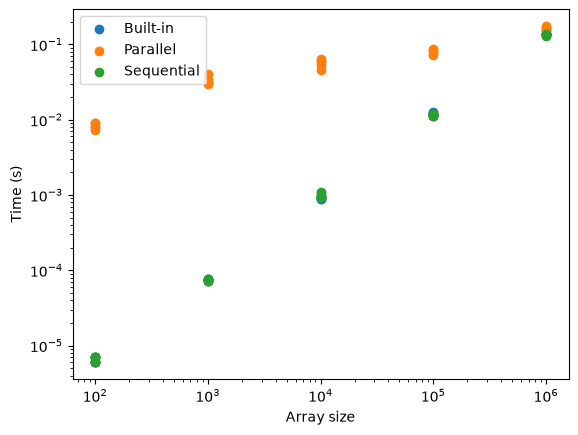

In [4]:
for t, g in df.groupby("Type"):
    plt.scatter(g["Size"], g["Time"], label=t)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Time (s)")
plt.legend();

I can't see the Built-in points, so let's give each algorithm its own shape.

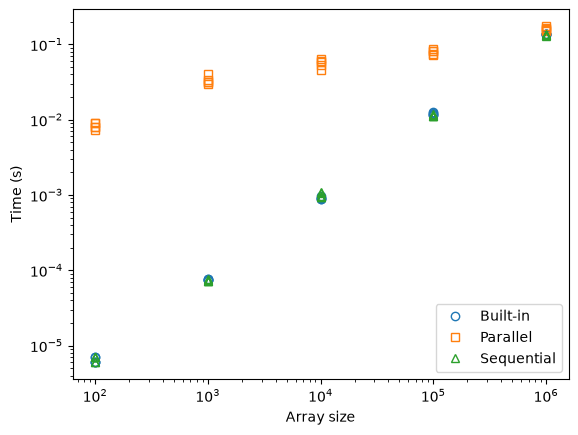

In [5]:
markers = {"Built-in": "o", "Parallel": "s", "Sequential": "^"}
for t, g in df.groupby("Type"):
    plt.plot(g["Size"], g["Time"], markers[t], fillstyle="none", label=t)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Time (s)")
plt.legend();

For better visibility on the plot, let's add lines connecting the points for each algorithm. This will help to visualize the trend of each algorithm's performance.

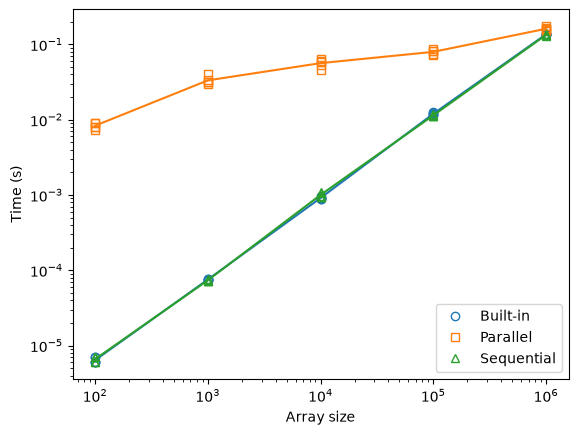

In [6]:
for i, (t, g) in enumerate(df.groupby("Type")):
    mean = g.groupby("Size")["Time"].mean()
    plt.plot(g["Size"], g["Time"], markers[t], fillstyle="none", color=f"C{i}", label=t)
    plt.plot(mean.index, mean.values, color=f"C{i}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Time (s)")
plt.legend();

It seems that the parallel algorithm is consistently slower than the sequential one across all input sizes. This is contrary to what was observed in `journal.org`, where the parallel algorithm outperformed the sequential one for larger input sizes (above ~400k).

maybe this is due to laptop hardware/software differences. but we can also notice that the two trends are close to each other at around 1M, which is the largest input size we tested. It would be interesting to see if the parallel algorithm starts to outperform the sequential one at even larger input sizes.

Let's make the same tests but with larger input sizes, but not adding too many sizes to not overload the laptop.

adding sizes 2M, 5M, 10M.

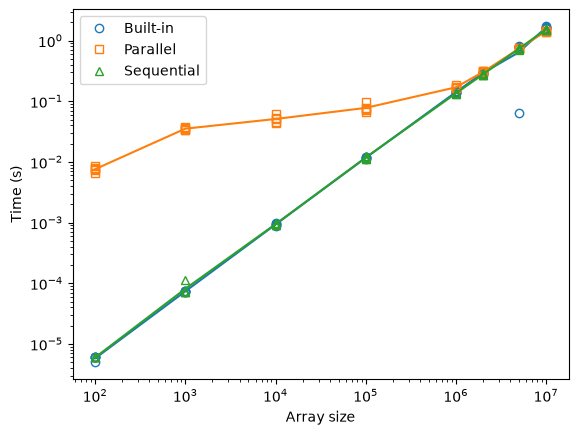

In [7]:
df2 = pd.read_csv("data/Rabii_2026-10-19/measurements_00:02.csv", skipinitialspace=True)
for i, (t, g) in enumerate(df2.groupby("Type")):
    mean = g.groupby("Size")["Time"].mean()
    plt.plot(g["Size"], g["Time"], markers[t], fillstyle="none", color=f"C{i}", label=t)
    plt.plot(mean.index, mean.values, color=f"C{i}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Time (s)")
plt.legend();

Need to investigate that aberrant point.

In [8]:
df2[df2["Size"] == 5000000]

,Size,Type,Time
90,5000000,Sequential,0.752178
91,5000000,Parallel,0.741670
92,5000000,Built-in,0.814779
93,5000000,Sequential,0.753225
94,5000000,Parallel,0.729854
95,5000000,Built-in,0.781414
96,5000000,Sequential,0.734353
97,5000000,Parallel,0.743709
98,5000000,Built-in,0.775089
99,5000000,Sequential,0.707608


Row 104 seems odd: Built-in took 0.063846 s, while the other four Built-in runs at 5M took about 0.78 s (12× slower). Maybe some error on the machine provoked it, so let's redo the same run.

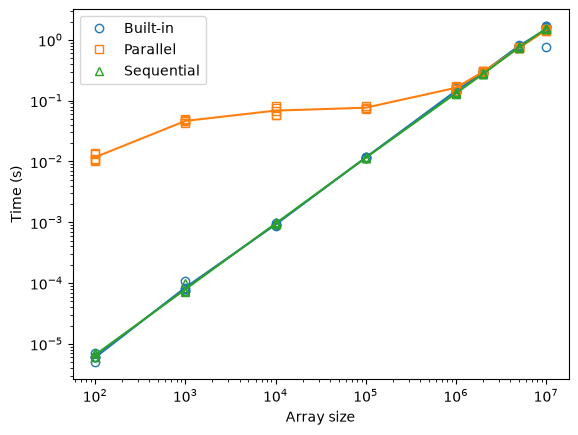

In [9]:
df3 = pd.read_csv("data/Rabii_2026-10-19/measurements_00:09.csv", skipinitialspace=True)
for i, (t, g) in enumerate(df3.groupby("Type")):
    mean = g.groupby("Size")["Time"].mean()
    plt.plot(g["Size"], g["Time"], markers[t], fillstyle="none", color=f"C{i}", label=t)
    plt.plot(mean.index, mean.values, color=f"C{i}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Time (s)")
plt.legend();

In [10]:
df3[df3["Size"] == 10000000]

,Size,Type,Time
104,10000000,Sequential,1.513047
105,10000000,Parallel,1.481359
106,10000000,Built-in,1.647411
107,10000000,Sequential,1.517740
108,10000000,Parallel,1.436421
109,10000000,Built-in,1.658105
110,10000000,Sequential,1.536342
111,10000000,Parallel,1.413193
112,10000000,Built-in,0.774689
113,10000000,Sequential,1.529446


we've got again an aberrant point at 10M, but not as bad as before. 

This can be signs that this experiment is hard to reproduce.

## Running each algorithm alone

The program runs the three algorithms one after the other in the same process, always in the same order. So one could have an impact on the next one (e.g. the parallel sort uses all the cores and heats up the CPU, and the built-in one always runs right after it).

To check that, I made a copy of the program (`src/parallelQuicksort_order_diff.c`) that runs only the algorithm given as 2nd argument (`sequential`, `parallelQuicksort` or `qsort`), and ran each algorithm in its own process, with 1 s of sleep between runs (`scripts/run_benchmarking_one_at_a_time.sh`). Same sizes as before, 5 runs each, one file per algorithm.

In [11]:
seq = pd.read_csv("data/Rabii_2026-10-21/measurements_21:13_sequential.csv", skipinitialspace=True)
par = pd.read_csv("data/Rabii_2026-10-21/measurements_21:13_parallelQuicksort.csv", skipinitialspace=True)
lib = pd.read_csv("data/Rabii_2026-10-21/measurements_21:13_qsort.csv", skipinitialspace=True)
df4 = pd.concat([seq, par, lib], ignore_index=True)
df4

,Size,Type,Time
0,100,Sequential,0.000006
1,100,Sequential,0.000006
2,100,Sequential,0.000006
3,100,Sequential,0.000006
4,100,Sequential,0.000006
...,...,...,...
114,10000000,Built-in,1.655974
115,10000000,Built-in,0.291581
116,10000000,Built-in,1.685869
117,10000000,Built-in,1.679760


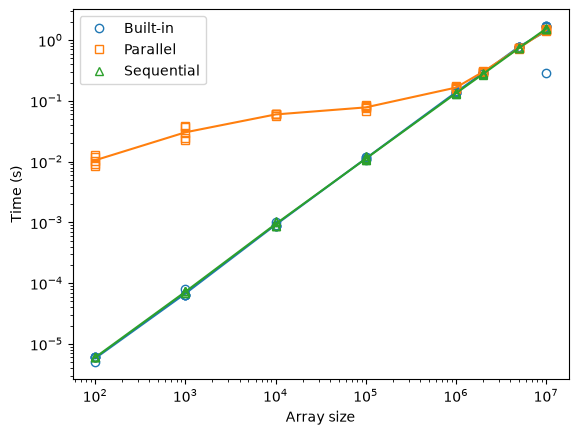

In [12]:
for i, (t, g) in enumerate(df4.groupby("Type")):
    mean = g.groupby("Size")["Time"].mean()
    plt.plot(g["Size"], g["Time"], markers[t], fillstyle="none", color=f"C{i}", label=t)
    plt.plot(mean.index, mean.values, color=f"C{i}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Time (s)")
plt.legend();

Note: there are only 4 Sequential points at 5M. In the `.txt` file, one run printed a negative time (`Sequential quicksort took: -0.607468 sec.`), and the perl script drops it since it only expects digits. A negative duration means the clock went backwards during the run: the program measures time with `gettimeofday` (the wall clock), which can be adjusted while it runs (WSL syncs its clock with Windows).

It looks the same as before, when all the algorithms ran in the same process, so we will continue our analysis.

## Memory usage

Now the second direction from the meeting: memory usage. Since the copy of the program runs one algorithm at a time, we can measure the memory of each algorithm alone: the peak memory of the process (max resident set size), given in KB by `/usr/bin/time -f "%M"` (`scripts/run_memory_benchmark.sh`). Same sizes as before, 5 runs each.

In [20]:
mem = pd.read_csv("data/Rabii_2026-10-21/memory_21:26.csv", skipinitialspace=True)
# same names as in the time plots
mem["Type"] = mem["Type"].replace({"sequential": "Sequential", "parallelQuicksort": "Parallel", "qsort": "Built-in"})
mem["MaxRSS"] = mem["MaxRSS"] / 1024  # KB -> MB
mem

,Size,Type,MaxRSS
0,100,Sequential,1.625000
1,100,Parallel,2.000000
2,100,Built-in,1.625000
3,100,Sequential,1.625000
4,100,Parallel,2.250000
...,...,...,...
115,10000000,Parallel,160.121094
116,10000000,Built-in,230.000000
117,10000000,Sequential,154.000000
118,10000000,Parallel,159.500000


In [21]:
mem.groupby(["Size", "Type"])["MaxRSS"].mean().unstack()

Type,Built-in,Parallel,Sequential
Size,,,
100,1.625,2.000000,1.625
1000,1.750,4.400000,1.750
10000,1.875,7.399219,1.875
100000,3.500,9.975000,2.975
1000000,24.000,22.725000,16.600
2000000,46.900,38.075000,32.000
5000000,115.625,82.022656,77.750
10000000,230.000,159.524219,154.000


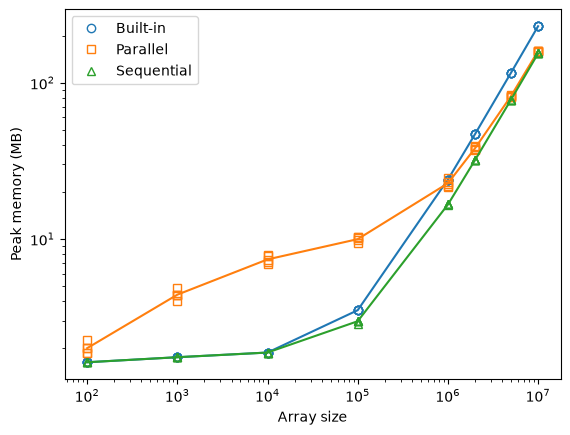

In [22]:
for i, (t, g) in enumerate(mem.groupby("Type")):
    mean = g.groupby("Size")["MaxRSS"].mean()
    plt.plot(g["Size"], g["MaxRSS"], markers[t], fillstyle="none", color=f"C{i}", label=t)
    plt.plot(mean.index, mean.values, color=f"C{i}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Peak memory (MB)")
plt.legend();

Most of it is just the two arrays the program allocates (the list and its backup, 2 × 8 bytes × N), whatever the algorithm. Let's remove them to see what each algorithm adds on top.

In [23]:
mem["Extra"] = mem["MaxRSS"] - 2 * 8 * mem["Size"] / 1024**2
mem.groupby(["Size", "Type"])["Extra"].mean().unstack()

Type,Built-in,Parallel,Sequential
Size,,,
100,1.623474,1.998474,1.623474
1000,1.734741,4.384741,1.734741
10000,1.722412,7.246631,1.722412
100000,1.974121,8.449121,1.449121
1000000,8.741211,7.466211,1.341211
2000000,16.382422,7.557422,1.482422
5000000,39.331055,5.728711,1.456055
10000000,77.412109,6.936328,1.412109


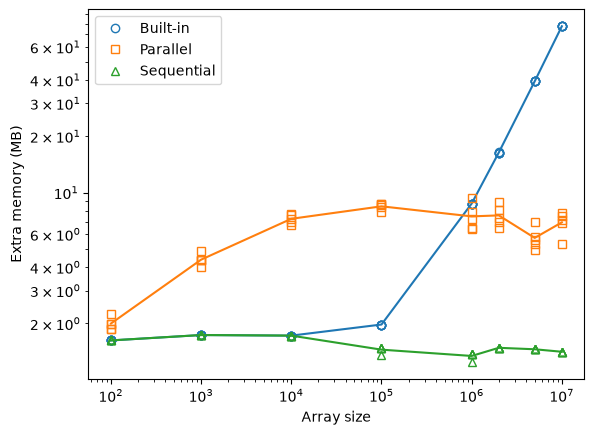

In [24]:
for i, (t, g) in enumerate(mem.groupby("Type")):
    mean = g.groupby("Size")["Extra"].mean()
    plt.plot(g["Size"], g["Extra"], markers[t], fillstyle="none", color=f"C{i}", label=t)
    plt.plot(mean.index, mean.values, color=f"C{i}")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Array size")
plt.ylabel("Extra memory (MB)")
plt.legend();

- Unlike the times, the memory is very stable: the 5 runs give almost the same value.
- Sequential: nothing more than the arrays (the ~1.5 MB left is the program itself).
- Parallel: the extra grows up to 10k (maybe because with small arrays the threads finish so fast that fewer of them exist at the same time), then stays around 6–8 MB whatever the size. It's the memory used by the threads. So for small arrays it's several times the sequential, but for large ones it's small (+4% at 10M).
- Built-in: the same as the sequential for small arrays, then the extra grows with the size: ~76 MB more than the sequential at 10M, which is one more copy of the array (8 bytes × N). Maybe because glibc's `qsort` is actually a merge sort that uses a temporary array.

So the parallel algorithm is not more memory efficient than the sequential one, but its extra memory doesn't grow with the size of the array.